### Import basic Libraries

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("C:\Auspify Technologies ML intern\Data\Dataset.csv")
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
print("Shape", df.shape)
print("-*" * 50)
print("Columns:", df.columns)
print("-*" * 50)
df.info()
print("-*" * 50)
print("Duplicates :", df.duplicated().sum())

Shape (8790, 10)
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
Columns: Index(['show_id', 'type', 'title', 'director', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in'],
      dtype='object')
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: 

### Prepare time-based features

In [4]:
df["date_added"] = pd.to_datetime(
    df["date_added"],
    errors="coerce"
)

In [5]:
forecast_df = df.dropna(
    subset=["date_added"]
).copy()

In [6]:
forecast_df["month"] = (
    forecast_df["date_added"]
    .dt.to_period("M")
)

monthly_titles = (
    forecast_df
    .groupby("month")
    .size()
    .sort_index()
)

monthly_titles.tail()

month
2021-05    132
2021-06    207
2021-07    257
2021-08    178
2021-09    183
Freq: M, dtype: int64

In [7]:
# Filling the missing month with zeros

monthly_titles = monthly_titles.to_timestamp()

monthly_titles = monthly_titles.asfreq("MS")

print(monthly_titles.isna().sum())

monthly_titles = monthly_titles.fillna(0)


57


### Analyze historical release patterns

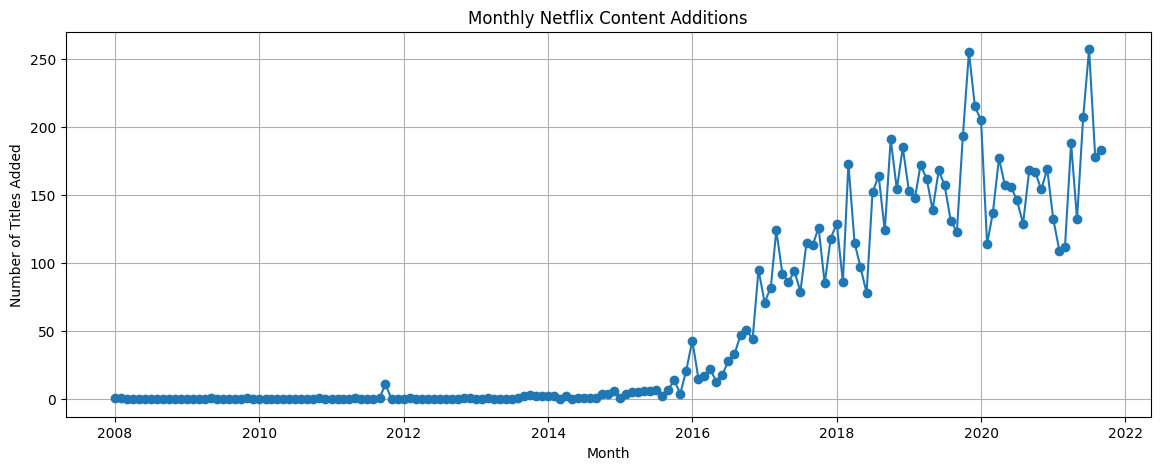

In [8]:

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_titles.index,
    monthly_titles.values,
    marker = 'o'
)

plt.title("Monthly Netflix Content Additions")
plt.xlabel("Month")
plt.ylabel("Number of Titles Added")

plt.grid(True)
plt.show()

### Creating a baseline forecasting model

In [9]:
y = monthly_titles.copy()

split_idx = int(len(y) * 0.9)

train = y.iloc[:split_idx]
test = y.iloc[split_idx:]

naive_predictions = pd.Series(
    train.iloc[-1],
    index=test.index
)

from sklearn.metrics import mean_absolute_error

naive_mae = mean_absolute_error(
    test,
    naive_predictions
)

print("Naive MAE:", naive_mae)

Naive MAE: 30.647058823529413


### Creating Lag Features

In [10]:
forecast_df_ml = monthly_titles.to_frame(
    name="total_titles"
)

forecast_df_ml["lag_1"] = (
    forecast_df_ml["total_titles"].shift(1)
)

forecast_df_ml["lag_2"] = (
    forecast_df_ml["total_titles"].shift(2)
)

forecast_df_ml["lag_3"] = (
    forecast_df_ml["total_titles"].shift(3)
)

forecast_df_ml = forecast_df_ml.dropna()

### Walk-Forward Validation

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

predictions = []
actuals = []

min_train_size = 12

for i in range(min_train_size, len(forecast_df_ml)):

    train_data = forecast_df_ml.iloc[:i]
    test_data = forecast_df_ml.iloc[i:i+1]

    X_train = train_data[
        ["lag_1", "lag_2", "lag_3"]
    ]

    y_train = train_data["total_titles"]

    X_test = test_data[
        ["lag_1", "lag_2", "lag_3"]
    ]

    y_test = test_data["total_titles"]

    model = RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)[0]

    predictions.append(pred)
    actuals.append(y_test.iloc[0])

walk_forward_mae = mean_absolute_error(
    actuals,
    predictions
)
walk_forward_mse = mean_squared_error(
    actuals,
    predictions
)
walk_forward_rmse = np.sqrt(mean_squared_error(
    actuals,
    predictions
))
walk_forward_r2 = r2_score(
    actuals,
    predictions
)

print("Walk-forward MAE:", walk_forward_mae)
print("Walk-forward MSE:", walk_forward_mse)
print("Walk-forward RMSE:", walk_forward_rmse)
print("Walk-forward R2:", walk_forward_r2)

Walk-forward MAE: 13.140475380063545
Walk-forward MSE: 581.6731335804193
Walk-forward RMSE: 24.1179006876722
Walk-forward R2: 0.8901254646576279


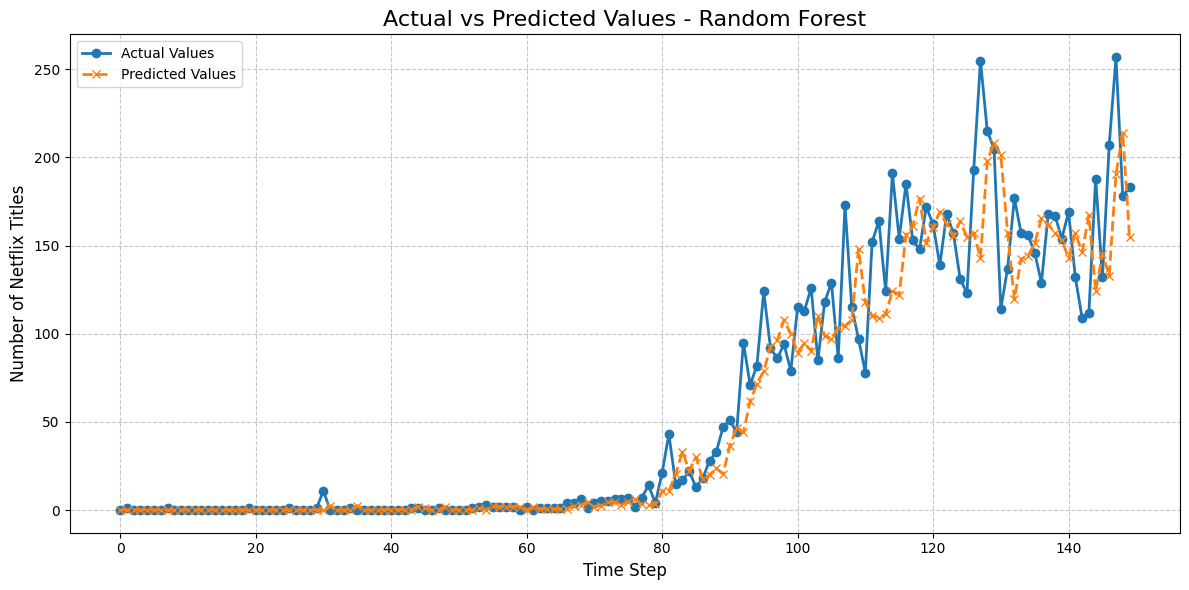

In [12]:
plt.figure(figsize=(12, 6))

plt.plot(actuals, label="Actual Values", marker="o", linewidth=2)
plt.plot(predictions, label="Predicted Values", marker="x", linestyle="--", linewidth=2)

plt.title("Actual vs Predicted Values - Random Forest", fontsize=16)
plt.xlabel("Time Step", fontsize=12)
plt.ylabel("Number of Netflix Titles", fontsize=12)

plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()

plt.show()

### Final Model

In [13]:
X = forecast_df_ml[
    ["lag_1", "lag_2", "lag_3"]
]

y = forecast_df_ml["total_titles"]



final_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

final_model.fit(
    X,
    y
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

### Generate future predictions

In [14]:
history = list(
    monthly_titles.values
)

future_predictions = []

for _ in range(12):

    lag_1 = history[-1]
    lag_2 = history[-2]
    lag_3 = history[-3]

    next_prediction = final_model.predict(
        [[lag_1, lag_2, lag_3]]
    )[0]

    # Counts cannot be negative.
    next_prediction = max(
        0,
        next_prediction
    )

    future_predictions.append(
        next_prediction
    )

    history.append(
        next_prediction
    )
    
    

future_dates = pd.date_range(
    start=monthly_titles.index[-1]
           + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

future_df = pd.DataFrame({
    "month": future_dates,
    "predicted_titles": future_predictions
})

print(future_df)

        month  predicted_titles
0  2021-10-01            145.32
1  2021-11-01            157.19
2  2021-12-01            159.21
3  2022-01-01            141.62
4  2022-02-01            141.76
5  2022-03-01            155.56
6  2022-04-01            155.55
7  2022-05-01            141.93
8  2022-06-01            143.14
9  2022-07-01            157.21
10 2022-08-01            155.65
11 2022-09-01            142.21


### Project Conclusion:

 This project helped me understand how to forecast future Netflix title additions using historical data. I started by loading and cleaning the dataset, then prepared time-based features and analyzed historical patterns. After that, I built a naive baseline model and used lag features to train a Random Forest model. I evaluated its performance using Walk-Forward Validation with MAE, MSE, RMSE, and R² scores. Finally, I trained the model using the available historical data and generated predictions for the next 12 months. Through this project, I gained practical experience in time-series forecasting, model evaluation, and predicting future trends using machine learning.
